# Independent AC baseline validation
Compute the previous baseline condition independently: inlet air 25 degC,
1.5 m/s, surface gap 4.5 mm, with cooling enabled at step-start times
180..1560 s (inclusive). Use inlet properties and the full-column correction
factor for the heat-transfer coefficient, matching the previous baseline method.
Use all 1920 valid heat-generation samples and export 1921 temperature states
from 0 to 1920 s into data/C0016. C0008_plot reads this baseline workbook.


In [ ]:
# read the power generation profile per time step

import csv
import os
import sys
import numpy as np
import pandas as pd

# data file name
PROJECT_ROOT = os.path.abspath("../..")
sys.path.append(PROJECT_ROOT)

import lib.BTMS_model as BTMS_model
import CoolProp.CoolProp as CP


file_name = os.path.join(PROJECT_ROOT, 'data', 'MD05E070207A1  data_power gen_single cell_Liu_20260421.xlsx')

# read the data from the csv file
time_steps = []
power_generation = []

df = pd.read_excel(file_name, sheet_name='Sheet1')

# extract the power generation data 
# The first spreadsheet row is a valid t=0 sample, not another header.
# Trim only trailing empty rows; do not compress an internal missing sample.
SIM_DURATION_S = 1920.0
DT = 1.0
NUM_STEPS = int(round(SIM_DURATION_S / DT))
if not np.isclose(NUM_STEPS * DT, SIM_DURATION_S):
    raise ValueError('SIM_DURATION_S must be an integer multiple of DT.')
q_source = pd.to_numeric(df['Qbat(W)'], errors='raise').to_numpy(dtype=float)
invalid = np.flatnonzero(~np.isfinite(q_source))
if len(invalid):
    first_invalid = int(invalid[0])
    if np.any(np.isfinite(q_source[first_invalid:])):
        raise ValueError('Qbat(W) contains an internal missing sample; check the source Excel.')
    q_source = q_source[:first_invalid]
time_s = np.arange(NUM_STEPS + 1, dtype=float) * DT
power_indices = np.floor(time_s[:-1]).astype(int)
if len(q_source) == 0 or power_indices[-1] >= len(q_source):
    raise ValueError('Not enough valid 1-s Qbat(W) samples for the full mission.')
power_generation_data = q_source[power_indices]
print(f'Heat input: {len(power_generation_data)} samples; temperature states: {len(time_s)}, 0..{time_s[-1]:g} s')


In [2]:
import numpy as np
from io import StringIO
import os

# Old results sent by LIU
# types = (
#     ('avg', 'MD05E070210A2  data_aircooling BTMS_temperature_avg.out'),
#     ('max', 'MD05E070211A2  data_aircooling BTMS_temperature_max.out'),
#     ('min', 'MD05E070212A2  data_aircooling BTMS_temperature_min.out')
# )
# col_map = {
#     'time_step': 0,
#     'flow_time': 1,
#     'report_def_0': 2
# }

# # A newer result sent by Liu, who added the periodic boundary condition and the set the 2nd order upwind scheme for the Fluent simulation, which is more accurate and closer to the experimental result.

# folder_name = 'HP02E030113A1  result_T_min, max, avg_air cooling_CFD_Liu_20260618'

# types = (
#     ('avg', os.path.join(folder_name, 'avg.out')),
#     ('max', os.path.join(folder_name, 'max.out')),
#     ('min', os.path.join(folder_name, 'min.out'))
# )

# col_map = {
#     'time_step': 0,
#     'flow_time': 2,
#     'report_def_0': 1
# }

# A new set of data sent by Liu, where the max and min values are calculated per battery cell, not the global ones. 

folder_name = 'HP02E030113A2  result_T_peak_avg per bat cell_air cooling_CFD_Liu_20260625'

types = (
    ('avg', os.path.join(folder_name, 'avg.out')),
    ('max', os.path.join(folder_name, 'max.out')),
    ('min', os.path.join(folder_name, 'min.out'))
)

col_map = {
    'time_step': 0,
    'flow_time': 1,
    'report_def_0': 2
}


temperature_cfd_data = {}  # dictionary to store CFD temperature data for each type

for t, file_name in types:
    file_name_cfd = os.path.join(PROJECT_ROOT, 'data', file_name)

    # Parse the Fluent report file: skip header lines starting with '"' and '(', read space-separated columns
    with open(file_name_cfd, 'r') as f:
        lines = [line.strip() for line in f if line.strip() and not line.strip().startswith('"') and not line.strip().startswith('(')]

    data_cfd = np.loadtxt(StringIO('\n'.join(lines)))
    time_step_cfd = data_cfd[:, col_map['time_step']].astype(int)
    flow_time_cfd = data_cfd[:, col_map['flow_time']]
    report_def_0_cfd = data_cfd[:, col_map['report_def_0']]  # avg battery temperature from CFD [K]
    
    temperature_cfd_data[t] = (flow_time_cfd, report_def_0_cfd)
    
print("CFD temperature data loaded for types:", list(temperature_cfd_data.keys()))
print("Example data for 'avg':", max(temperature_cfd_data['avg'][1]))  # print first 5 entries for 'avg' type to verify



CFD temperature data loaded for types: ['avg', 'max', 'min']
Example data for 'avg': 320.1392930834928


In [ ]:
dt = DT # time step in seconds

# battery parameters foundin [[parkpark2025RefinedAircooled]]
# properties for battery type INR18650-30Q
T_bat_init = 25 # initial battery temperature in Celsius
cp_bat = 830 # specific heat capacity of the battery in J/(kg°C) 
m_bat = 48e-3 # mass of the battery in kg
D_bat = 18e-3 # diameter of the battery in meters
H_bat = 65e-3 # height of the battery in meters
A_battery = np.pi * D_bat * H_bat # surface area of the battery in m^2

num_time_steps = NUM_STEPS + 1 # initial state plus all integrations
# calculate the battery temperature over time
T_bat = np.zeros(num_time_steps)
T_bat[0] = T_bat_init

for i in range(1, num_time_steps):
    # calculate the temperature change based on the power generation and battery parameters
    dT = (power_generation_data[i-1] * dt) / (m_bat * cp_bat)
    T_bat[i] = T_bat[i-1] + dT      


In [4]:

# Initial conditions and parameters

# V_air_nom = 241 # nominal air velocity in km/h for the cooling system (example value, adjust as needed)
# V_air = V_air_nom / 3.6 # convert nominal air velocity to m/s

V_air_in = 1.5 # air inlet velocity

height = 457
T_air = 25 # ambient air temperature in Celsius

# T_air += 457 * (-6.5/1000)  # Adjust temperature based on altitude (example value, adjust as needed)
T_air_K = T_air + 273.15 # convert to Kelvin

p_air = 101325 # ambient air pressure in Pa

N_r, N_c = 16, 20 # number of rows and columns in the battery arrangement for a single module (example values, adjust as needed)

S_T = 1.25 * D_bat # spacing between battery rows in meters (example value, adjust as needed)

W_module = D_bat + (N_r - 1) * S_T # width of the battery module in meters (example calculation, adjust as needed)

A_air = W_module * H_bat # cross-sectional area of a single module of the air flow path in m^2

A_air_row = A_air / N_r # cross-sectional area of the air flow path for each row of the battery arrangement in m^2

fluid = 'Air'

t_cruise_start = 180 # time step when the cruise phase starts (example value, adjust as needed)
t_cruise_end = 1560 # time step when the cruise phase ends (example value, adjust as needed)


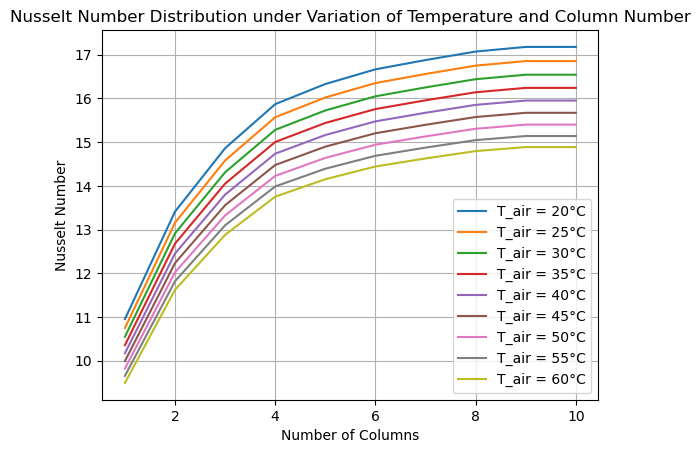

In [5]:
# Test the Nusselt number distribution under the variation of temperature and column number

import lib.BTMS_model as BTMS_model
import CoolProp.CoolProp as CP

T_air_test_array = np.arange(20, 61, 5)  # Test for air temperatures from 20°C to 60°C in steps of 5°C
num_col_array = np.arange(1, 11)  # Test for number of columns from 1 to 10

# data structure to store results
results = {}

for T_air_test in T_air_test_array:  # Test for air temperatures from 20°C to 60°C in steps of 5°C
    results_T = []
    
    for num_col in num_col_array:  # Test for number of columns from 1 to 10
        
        T_air_K_test = T_air_test + 273.15  # Convert to Kelvin
        mu_air_test = CP.PropsSI('V', 'T', T_air_K_test, 'P', p_air, fluid)
        rho_air_test = CP.PropsSI('D', 'T', T_air_K_test, 'P', p_air, fluid)
        cp_air_test = CP.PropsSI('C', 'T', T_air_K_test, 'P', p_air, fluid)
        k_air_test = CP.PropsSI('L', 'T', T_air_K_test, 'P', p_air, fluid)
        Pr_air_test = cp_air_test * mu_air_test / k_air_test
        
        V_air_test = V_air_in  # Assuming the same air velocity for testing
        Re_air_test = (rho_air_test * V_air_test * D_bat) / mu_air_test
        
        eps_test = BTMS_model.select_correction_factor(no_col=num_col, Re=Re_air_test)
        Nu_air_test = BTMS_model.zukauskas_nusellet(Re_air_test, Pr_air_test, eps_test, Pr_air_test)
        
        htc_air_test = (Nu_air_test * k_air_test) / D_bat
        
        results_T.append(Nu_air_test)  # Store the Nusselt number for this combination of air temperature and number of columns
    
    results[T_air_test] = results_T
    
    
# plot the simulation results for Nusselt number distribution under the variation of temperature and column number
import matplotlib.pyplot as plt

# Plot the Nusselt number distribution
for T_air_test, Nu_values in results.items():
    plt.plot(num_col_array, Nu_values, label=f"T_air = {T_air_test}°C")

plt.xlabel("Number of Columns")
plt.ylabel("Nusselt Number")
plt.title("Nusselt Number Distribution under Variation of Temperature and Column Number")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Fixed inlet-air properties and HTC, matching the previous baseline method.
mu_air = CP.PropsSI('V', 'T', T_air_K, 'P', p_air, fluid)
rho_air = CP.PropsSI('D', 'T', T_air_K, 'P', p_air, fluid)
cp_air = CP.PropsSI('C', 'T', T_air_K, 'P', p_air, fluid)
k_air = CP.PropsSI('L', 'T', T_air_K, 'P', p_air, fluid)
Pr_air = cp_air * mu_air / k_air
V_air_char = V_air_in
Re_air = rho_air * V_air_char * D_bat / mu_air
eps = BTMS_model.select_correction_factor(no_col=N_c, Re=Re_air)
Nu_air = BTMS_model.zukauskas_nusellet(Re_air, Pr_air, eps, Pr_air)
htc_air = Nu_air * k_air / D_bat
SOLVER_TOL = 1e-6
SOLVER_MAXITER = 1000
print(f'Baseline: V_air={V_air_in:g} m/s, gap={(S_T-D_bat)*1e3:g} mm, h={htc_air:.6f} W/(m2 K)')


In [7]:

# battery temperature under air cooling
T_bat_0D = np.ones(num_time_steps) * T_bat_init
T_air_out_0D = np.ones(num_time_steps) * T_air # to store the outlet air temperature for analysis
t = 0 # initialize time variable

Q_cool_profile_0D = np.zeros(num_time_steps) # to store the cooling power profile for analysis

for i in range(1, num_time_steps):
    
    # enable the air cooling in the cruise phase only 
    T_air_in = T_air 
    is_cool = t >= t_cruise_start and t <= t_cruise_end # determine if cooling is enabled based on the current time step and the defined cruise phase 
       
    if is_cool and T_bat_0D[i-1] > T_air_in: # only calculate cooling power if cooling is enabled and the battery temperature is higher than the air inlet temperature
        Q_cool = htc_air * A_battery * (T_bat_0D[i-1] - T_air_in) # an approximates calculation
    else:
        Q_cool = 0
        
    # if(Q_cool > power_generation_data[i-1]):
    #     Q_cool = power_generation_data[i-1] # limit the cooling power to not exceed the power generation for this time step, adjust as needed based on specific assumptions for the 0D model
    
    dT_bat = (power_generation_data[i-1] - Q_cool) * dt / (m_bat * cp_bat)  # calculate the change in battery temperature based on the power generation, cooling power, and battery parameters
    T_bat_0D[i] = T_bat_0D[i-1] + dT_bat  # update the battery temperature based on the calculated change in temperature
    
    dT_air = Q_cool * N_c * N_r / (A_air * V_air_in * rho_air * cp_air)  # calculate the change in air temperature based on the cooling power and the air flow parameters
    T_air_out_0D[i] = T_air_in + dT_air  # calculate the air outlet temperature based on the cooling power and the air flow parameters
    Q_cool_profile_0D[i] = Q_cool # store the cooling power for this time step for analysis  
    
    t = t + dt # update time variable


In [ ]:
# Independently solve the baseline coolant/battery energy balance.
import io
import contextlib

num_segment = N_c
T_bat_history = np.full((num_time_steps, num_segment), T_bat_init, dtype=float)
T_air_history = np.full((num_time_steps, num_segment), T_air, dtype=float)
Q_cool_history = np.zeros((num_time_steps, num_segment), dtype=float)
Q_cool_history_fd_total = np.zeros(num_time_steps, dtype=float)
cooling_active_history = np.zeros(NUM_STEPS, dtype=bool)
htc_seg = np.full(num_segment, htc_air)
debug = False

for k in range(NUM_STEPS):
    t = time_s[k]
    i = k + 1
    is_cooling = (t >= t_cruise_start) and (t <= t_cruise_end)
    cooling_active_history[k] = is_cooling
    T_bat_pre = T_bat_history[k].copy()
    T_cool_pre = T_air_history[k].copy()
    args = {
        'num_seg': num_segment, 'num_seg_bat': num_segment,
        'dt': dt, 'T_bat_pre': T_bat_pre, 'T_cool_pre': T_cool_pre,
        'u_cool_in': V_air_in, 'p_cool': p_air, 'fluid_cool': fluid,
        'A_HT_seg': A_battery, 'A_cool_cs': A_air_row,
        'm_bat': m_bat, 'cp_bat': cp_bat, 'D_bat': D_bat,
        'T_cool_in': T_air, 'T_cool_out': max(float(T_cool_pre[-1]), T_air),
        'htc_cool': htc_seg, 'cp_cool': cp_air, 'rho_cool': rho_air,
        'is_cool': is_cooling, 'Q_gen': float(power_generation_data[k]),
        'num_cell_seg': 1.0, 'debug': debug,
    }
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            T_dist = BTMS_model.solve_coolant_temperature_distribution(
                args, tol=SOLVER_TOL, maxiter=SOLVER_MAXITER, debug=debug)
    except Exception as exc:
        raise RuntimeError(f'C0016 baseline failed at t={t:g} s, Q_gen={power_generation_data[k]:g} W') from exc
    T_dist = np.asarray(T_dist, dtype=float)
    if T_dist.shape != (2 * num_segment,) or not np.all(np.isfinite(T_dist)):
        raise FloatingPointError(f'Invalid baseline temperature solution at t={t:g} s.')
    T_air_history[i] = T_dist[:num_segment]
    T_bat_history[i] = T_dist[num_segment:]
    Q_cool_HT, Q_cool_change, Q_bat = BTMS_model.cal_energy_balance(T_dist, args)
    Q_cool_history[i] = Q_cool_HT
    Q_cool_history_fd_total[i] = Q_cool_HT.sum()
    # Check the same battery energy balance used by the solver.
    if not np.allclose(Q_bat + Q_cool_HT, power_generation_data[k] * dt,
                       atol=1e-5, rtol=1e-5):
        raise RuntimeError(f'Baseline energy balance did not converge at t={t:g} s.')

print(f'Baseline completed: {NUM_STEPS} steps, final time={time_s[-1]:g} s, '
      f'Tmax={T_bat_history.max():.6f} degC, '
      f'DeltaTmax={np.ptp(T_bat_history, axis=1).max():.6f} degC')


In [ ]:
# Export every valid state without truncating the final two seconds.
# Preserve Sheet1's Time Step / T_bat / T_air schema used by C0008_plot.
CASE_ID = 'C0016'
CASE_NAME = 'C0016R00_PARK25_AC_THERM_1D_VAL'
if T_bat_history.shape != (NUM_STEPS + 1, num_segment):
    raise ValueError('Baseline battery history has an unexpected shape.')
if not np.all(np.isfinite(T_bat_history)) or not np.all(np.isfinite(T_air_history)):
    raise FloatingPointError('Baseline contains invalid values; the existing Excel was not overwritten.')
T_bat_df = pd.DataFrame(T_bat_history, columns=[f'T_bat {i+1}' for i in range(num_segment)])
for i in range(num_segment):
    T_bat_df[f'T_air {i+1}'] = T_air_history[:, i]
T_bat_df.insert(0, 'Time Step', np.arange(num_time_steps, dtype=int))
summary_df = pd.DataFrame([{
    'model': 'Baseline', 'source_notebook': CASE_NAME + '.ipynb',
    'V_air_m_s': V_air_in, 'T_air_in_C': T_air, 's_gap_mm': (S_T - D_bat) * 1e3,
    'cooling_mode': 'cruise_only', 'cruise_start_s': t_cruise_start, 'cruise_end_s': t_cruise_end,
    'simulation_duration_s': SIM_DURATION_S, 'dt_s': dt,
    'Re_air': Re_air, 'Nu_air': Nu_air, 'h_air_W_m2K': htc_air,
    'Tmax_mission_C': float(T_bat_history.max()),
    'DeltaT_mission_max_C': float(np.ptp(T_bat_history, axis=1).max()),
}])
result_dir = os.path.join(PROJECT_ROOT, 'data', CASE_ID)
os.makedirs(result_dir, exist_ok=True)
file_name = os.path.join(result_dir, f'{CASE_NAME}.xlsx')
temporary_file = os.path.splitext(file_name)[0] + '.tmp.xlsx'
try:
    with pd.ExcelWriter(temporary_file, engine='openpyxl') as writer:
        T_bat_df.to_excel(writer, sheet_name='Sheet1', index=False)
        summary_df.to_excel(writer, sheet_name='Summary', index=False)
        for sheet in writer.sheets.values():
            sheet.freeze_panes = 'A2'
            sheet.auto_filter.ref = sheet.dimensions
    os.replace(temporary_file, file_name)
finally:
    if os.path.exists(temporary_file):
        os.remove(temporary_file)
print(f'Baseline Excel saved: {file_name}; {len(T_bat_df)} states, 0..{time_s[-1]:g} s')
